# Senate Stars: Winners

Which 2026 Senate nominees **won their race** and also **ran at or ahead of the national shift**?

- **Swing** = 2026 Senate margin (D − R) minus the 2024 presidential margin (Harris − Trump) in the same state.
- **National shift** = +13.9 points: the 2026 House popular vote (D+12.4, unofficial as of Nov 6, 2026) minus the 2024 presidential popular vote (R+1.5).
- A candidate qualifies if they **won** (or lead an uncalled race) and their **swing is greater than or equal to the national shift**.

The notebook works step by step: load the data, compute each candidate's swing, apply the two filters, then draw the chart.

Data: 2026 tallies from AP/DDHQ as of Nov 6, 2026 (some states still counting). Mississippi is not yet called by AP; Colom leads and is included, marked with *. Alaska (Peltola) is uncalled and falls below the shift line.

## Step 1: Load the data

Each row is one 2026 Democratic Senate nominee:

- `dem`, `rep`: 2026 vote share (%) for the Democrat and the top Republican
- `pres24`: the state's 2024 presidential margin, Harris − Trump (points)
- `flipped`: 1 if the seat would move from Republican to Democratic
- `result`: Won, Lost, Leading (uncalled, Democrat ahead) or Uncalled

In [1]:
import io
import pandas as pd

In [2]:
DATA = """st,cand,dem,rep,pres24,flipped,result
AL,Wess,45.3,54.7,-30.59,0,Lost
AK,Peltola,48.2,47.9,-13.13,0,Uncalled
AR,Shoffner,42.4,54.3,-30.64,0,Lost
CO,Hickenlooper,60.2,35.3,10.99,0,Won
DE,Coons,63.6,36.4,14.74,0,Won
FL,Nixon,48.0,50.9,-13.10,0,Lost
GA,Ossoff,59.0,41.0,-2.19,0,Won
IL,Stratton,61.0,37.4,10.98,0,Won
IA,Turek,50.5,46.4,-13.26,1,Won
KS,Hamilton,50.9,45.8,-16.12,1,Won
KY,Booker,42.9,55.0,-30.55,0,Lost
LA,Davis,49.1,50.9,-22.01,0,Lost
ME,Jackson,53.1,46.9,6.94,1,Won
MA,Markey,63.4,32.1,25.34,0,Won
MI,El-Sayed,52.5,45.5,-1.41,0,Won
MN,Flanagan,53.8,43.6,4.26,0,Won
MS,Colom,49.0,48.8,-22.89,1,Leading
NH,Pappas,55.9,42.2,2.79,0,Won
NJ,Booker,62.3,35.2,5.91,0,Won
NM,Luján,63.2,36.8,6.00,0,Won
NC,Cooper,58.7,39.1,-3.22,1,Won
OH,Brown,50.0,45.2,-11.21,1,Won
OK,Thomas,39.3,57.2,-34.26,0,Lost
OR,Merkley,57.6,39.4,14.39,0,Won
RI,Reed,66.9,29.3,13.85,0,Won
SC,Andrews,51.2,46.8,-17.87,1,Won
TN,Bradshaw,42.9,55.1,-29.72,0,Lost
TX,Talarico,55.1,43.0,-13.69,1,Won
VA,Warner,61.1,38.9,5.81,0,Won
WV,Anderson,37.9,58.3,-41.87,0,Lost
WY,Byrd,34.8,65.2,-46.22,0,Lost"""

df = pd.read_csv(io.StringIO(DATA))
print(f"{len(df)} Democratic nominees loaded")
df.head()

31 Democratic nominees loaded


,st,cand,dem,rep,pres24,flipped,result
0,AL,Wess,45.3,54.7,-30.59,0,Lost
1,AK,Peltola,48.2,47.9,-13.13,0,Uncalled
2,AR,Shoffner,42.4,54.3,-30.64,0,Lost
3,CO,Hickenlooper,60.2,35.3,10.99,0,Won
4,DE,Coons,63.6,36.4,14.74,0,Won


## Step 2: The national shift

The yardstick every candidate is measured against: how much the national vote moved toward Democrats between the 2024 presidential race and the 2026 House vote.

In [3]:
HOUSE_2026 = 12.4  # 2026 House popular vote, D − R (unofficial, Nov 6, 2026)
PRES_2024 = -1.5  # 2024 presidential popular vote, D − R

NAT_SHIFT = HOUSE_2026 - PRES_2024
print(f"National shift: +{NAT_SHIFT:.1f} points toward Democrats")

National shift: +13.9 points toward Democrats


## Step 3: Each candidate's swing

First the 2026 Senate margin (Democrat minus Republican), then the swing: how far that margin moved from the state's 2024 presidential margin.

In [4]:
df["margin26"] = df.dem - df.rep
df["swing"] = df.margin26 - df.pres24

In [5]:
df.sort_values("swing", ascending=False)[
    ["cand", "st", "pres24", "margin26", "swing", "result"]
].round(2)

,cand,st,pres24,margin26,swing,result
27,Talarico,TX,-13.69,12.1,25.79,Won
24,Reed,RI,13.85,37.6,23.75,Won
16,Colom,MS,-22.89,0.2,23.09,Leading
20,Cooper,NC,-3.22,19.6,22.82,Won
25,Andrews,SC,-17.87,4.4,22.27,Won
29,Anderson,WV,-41.87,-20.4,21.47,Lost
9,Hamilton,KS,-16.12,5.1,21.22,Won
0,Wess,AL,-30.59,-9.4,21.19,Lost
18,Booker,NJ,5.91,27.1,21.19,Won
19,Luján,NM,6.00,26.4,20.40,Won


## Step 4: Filter 1, keep the winners

Keep candidates who won, plus Colom, who leads an uncalled race.

In [6]:
winners = df[df.result.isin(["Won", "Leading"])]
print(f"{len(winners)} of {len(df)} nominees won or lead")

21 of 31 nominees won or lead


## Step 5: Filter 2, keep those at or above the shift line

Of the winners, keep those whose swing is greater than or equal to the national shift. (Add a tolerance for floating-point rounding; Hickenlooper clears the line by 0.01.)

In [7]:
stars = winners[winners.swing >= NAT_SHIFT - 1e-9].copy()
stars["vs_shift"] = stars.swing - NAT_SHIFT
print(f"{len(stars)} Democratic Senate Stars")

13 Democratic Senate Stars


In [8]:
stars.sort_values("swing", ascending=False)[
    ["cand", "st", "pres24", "swing", "vs_shift", "flipped", "result"]
].round(2)

,cand,st,pres24,swing,vs_shift,flipped,result
27,Talarico,TX,-13.69,25.79,11.89,1,Won
24,Reed,RI,13.85,23.75,9.85,0,Won
16,Colom,MS,-22.89,23.09,9.19,1,Leading
20,Cooper,NC,-3.22,22.82,8.92,1,Won
25,Andrews,SC,-17.87,22.27,8.37,1,Won
9,Hamilton,KS,-16.12,21.22,7.32,1,Won
18,Booker,NJ,5.91,21.19,7.29,0,Won
19,Luján,NM,6.00,20.40,6.50,0,Won
6,Ossoff,GA,-2.19,20.19,6.29,0,Won
8,Turek,IA,-13.26,17.36,3.46,1,Won


## Step 6: Prepare the chart data

Sort smallest swing first (matplotlib draws bars bottom-up, so the biggest swing ends up on top), build each row's label with the state's 2024 lean, and pick a color by seat type.

In [9]:
d = stars.sort_values("swing").reset_index(drop=True)

In [10]:
def lean(margin):
    """2024 presidential margin as 'D+x' or 'R+x'."""
    return f"D+{margin:.1f}" if margin > 0 else f"R+{-margin:.1f}"


d["label"] = d.cand + " · " + d.st + " (" + d.pres24.map(lean) + ")"
d.loc[d.result == "Leading", "label"] += "*"  # uncalled race

In [11]:
COLORS = {"Flipped R→D": "#199e70", "Held D seat": "#3987e5"}

d["seat"] = d.flipped.map({1: "Flipped R→D", 0: "Held D seat"})
d["color"] = d.seat.map(COLORS)
d[["label", "swing", "vs_shift", "seat"]].round(2)

,label,swing,vs_shift,seat
0,Hickenlooper · CO (D+11.0),13.91,0.01,Held D seat
1,Brown · OH (R+11.2),16.01,2.11,Flipped R→D
2,Warner · VA (D+5.8),16.39,2.49,Held D seat
3,Turek · IA (R+13.3),17.36,3.46,Flipped R→D
4,Ossoff · GA (R+2.2),20.19,6.29,Held D seat
5,Luján · NM (D+6.0),20.40,6.50,Held D seat
6,Booker · NJ (D+5.9),21.19,7.29,Held D seat
7,Hamilton · KS (R+16.1),21.22,7.32,Flipped R→D
8,Andrews · SC (R+17.9),22.27,8.37,Flipped R→D
9,Cooper · NC (R+3.2),22.82,8.92,Flipped R→D


## Step 7: Build the chart

The chart is assembled from small drawing functions, one per layer, then put together in the last cell. First, the dark theme and fonts.

In [12]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

SURF = "#1a1a19"  # background
INK = "#f0efec"  # primary text
INK2 = "#c3c2b7"  # secondary text
MUTED = "#898781"  # footnote
GRID = "#2c2c2a"  # gridlines
BASE = "#383835"  # x-axis line

plt.rcParams["font.family"] = ["Helvetica Neue", "Arial", "DejaVu Sans"]

Layer 1: one bar per candidate, with its swing and its margin over the shift written at the end of the bar.

In [13]:
def draw_bars(ax):
    ax.barh(d.index, d.swing, height=0.62, color=d.color, zorder=3)
    for i, r in d.iterrows():
        ax.text(
            r.swing + 0.35,
            i,
            f"{r.swing:+.1f}   ({r.vs_shift:+.1f} vs shift)",
            va="center",
            ha="left",
            fontsize=8.5,
            color=INK2,
            zorder=4,
        )

Layer 2: candidate names on the y-axis (flipped seats in bold) and the dashed national-shift line.

In [14]:
def draw_labels_and_shift_line(ax):
    ax.set_yticks(d.index, d.label, color=INK, fontsize=9.5)
    for tick, flipped in zip(ax.get_yticklabels(), d.flipped):
        if flipped:
            tick.set_fontweight("bold")

    ax.axvline(NAT_SHIFT, color=INK2, lw=1.2, ls=(0, (4, 3)), zorder=5)
    ax.text(
        NAT_SHIFT,
        len(d) - 0.3,
        f" national shift +{NAT_SHIFT:.1f}",
        color=INK2,
        fontsize=8.5,
        va="bottom",
    )

Layer 3: axis limits, gridlines, a quiet frame and the legend.

In [15]:
def style_axes(ax):
    ax.set_facecolor(SURF)
    ax.set_ylim(-0.7, len(d) + 0.5)
    ax.set_xlim(0, d.swing.max() + 9)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0f}"))
    ax.xaxis.grid(True, color=GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASE)
    ax.tick_params(axis="both", length=0, colors=INK2)
    ax.legend(
        handles=[Patch(color=c, label=k) for k, c in COLORS.items()],
        loc="lower right",
        frameon=False,
        fontsize=8.5,
        labelcolor=INK2,
    )

Layer 4: title, subtitle and footnote.

In [18]:
n_flips = int(d.flipped.sum())
n_holds = len(d) - n_flips

TITLE = "2026 Senate Stars — Overperforming Winners"
SUBTITLE = (
    f"The {len(d)} Democrats who beat the +{NAT_SHIFT:.1f} national shift "
    f"and won (or lead) their race ({n_flips} flips, {n_holds} holds)"
)
FOOTNOTE = (
    "Bar = swing vs. 2024 presidential margin.\n"
    f"National shift = House popular vote D+{HOUSE_2026} (unofficial, Nov 6, 2026) "
    f"vs. 2024 presidential R+{-PRES_2024}.\n"
    "* MS not yet called by AP as of Nov 6, 2026; Colom leads."
)


def add_titles(fig):
    h = fig.get_figheight()
    fig.text(
        0.015, 1 - 0.25 / h, TITLE, fontsize=15, fontweight="bold", color=INK, va="top"
    )
    fig.text(0.015, 1 - 0.62 / h, SUBTITLE, fontsize=10, color=INK2, va="top")
    fig.text(0.015, 0.1 / h, FOOTNOTE, fontsize=7.5, color=MUTED, va="bottom")
    fig.tight_layout(rect=(0, 0.75 / h, 1, 1 - 0.95 / h))

## Step 8: Draw it

Stack the four layers on one figure, save a PNG next to the notebook, and show it.

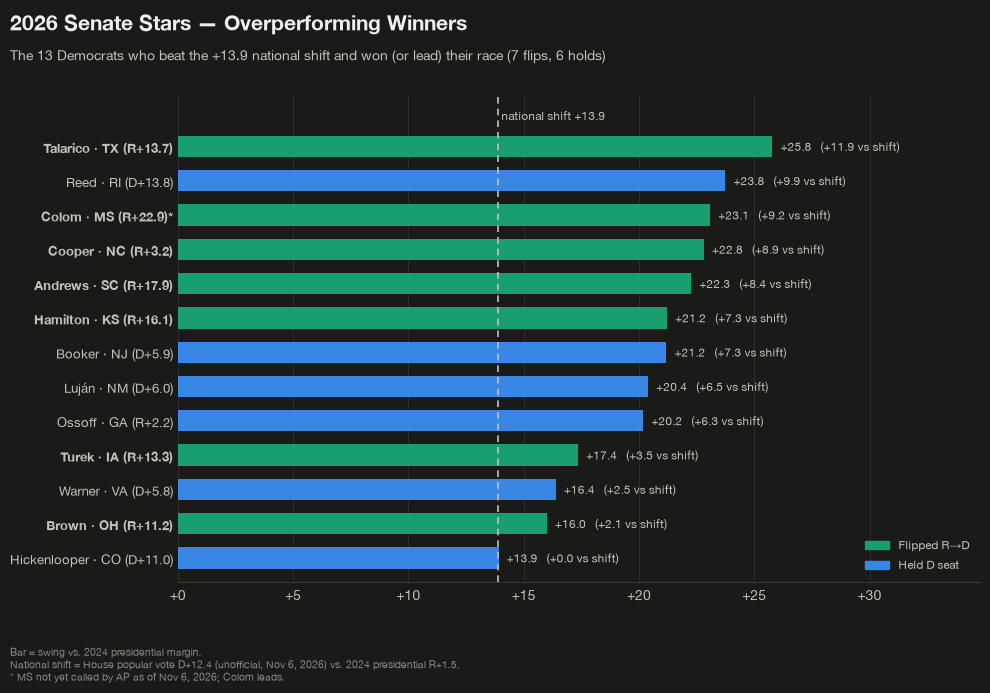

In [19]:
fig, ax = plt.subplots(figsize=(10, 0.36 * len(d) + 2.4), facecolor=SURF)

draw_bars(ax)
draw_labels_and_shift_line(ax)
style_axes(ax)
add_titles(fig)

fig.savefig("democratic_senate_stars_winners.png", dpi=200, facecolor=SURF)
plt.show()